In [1]:
pip install scikit-learn matplotlib numpy pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
"""
Credit Score Classification
Source : https://www.kaggle.com/datasets/parisrohan/credit-score-classification
input: credit_score.csv
output: credit_score_cleaned.csv
"""


'\nCredit Score Classification: Data Mining ETL & Pre-processing Pipeline\n\nSource: https://www.kaggle.com/datasets/parisrohan/credit-score-classification\nInput:  credit_score.csv \nOutput: credit_score_cleaned.csv\n\nInstall dependencies:\n    pip install pandas numpy matplotlib scikit-learn\n\n'

In [19]:

#step 1: Data pre processing 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from pathlib import Path

pd.set_option("display.max_columns",50)
pd.set_option("display.float_format",lambda x: f"{x:,.3f}")
INPUT_FILE = Path("credit_score.csv")
OUTPUT_FILE = Path("credit_score_cleaned.csv")
if not INPUT_FILE.exists():
    raise FileNotFoundError(
        "file is not present within same directory!"
    )
data = pd.read_csv(INPUT_FILE,low_memory = False)
df = data.copy()
print(data.head(10))


       ID Customer_ID     Month             Name   Age          SSN  \
0  0x1602   CUS_0xd40   January    Aaron Maashoh    23  821-00-0265   
1  0x1603   CUS_0xd40  February    Aaron Maashoh    23  821-00-0265   
2  0x1604   CUS_0xd40     March    Aaron Maashoh  -500  821-00-0265   
3  0x1605   CUS_0xd40     April    Aaron Maashoh    23  821-00-0265   
4  0x1606   CUS_0xd40       May    Aaron Maashoh    23  821-00-0265   
5  0x1607   CUS_0xd40      June    Aaron Maashoh    23  821-00-0265   
6  0x1608   CUS_0xd40      July    Aaron Maashoh    23  821-00-0265   
7  0x1609   CUS_0xd40    August              NaN    23    #F%$D@*&8   
8  0x160e  CUS_0x21b1   January  Rick Rothackerj   28_  004-07-5839   
9  0x160f  CUS_0x21b1  February  Rick Rothackerj    28  004-07-5839   

  Occupation Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  \
0  Scientist      19114.12              1,824.843                  3   
1  Scientist      19114.12                    NaN                  3   
2 

In [20]:

#dataset profiling and initial auditing
print("dataset dimensions:", data.shape)
print("\ndata types:")
print(data.dtypes.astype(str).value_counts().rename("number of columns").to_frame())

Profile = pd.DataFrame({
    "Data type" : data.dtypes.astype(str),
    "missing values" : data.isna().sum(),
    "missing %": (data.isna().mean()*100).round(2),
    "unique values": data.nunique(dropna = True)
}).sort_values("missing values", ascending = False)
print(Profile)

print("total duplicate rows: ", data.duplicated().sum())
print("\n target class counts: ")
print(data["Credit_Score"].value_counts(dropna = False).to_frame("Records"))

print("\nNumerical description before cleaning: ")
print(data.describe(include="all").T.head(20))



dataset dimensions: (100000, 28)

data types:
         number of columns
str                     20
float64                  4
int64                    4
                         Data type  missing values  missing %  unique values
Monthly_Inhand_Salary      float64           15002     15.000          13235
Type_of_Loan                   str           11408     11.410           6260
Name                           str            9985      9.980          10139
Credit_History_Age             str            9030      9.030            404
Num_of_Delayed_Payment         str            7002      7.000            749
Amount_invested_monthly        str            4479      4.480          91049
Num_Credit_Inquiries       float64            1965      1.960           1223
Monthly_Balance                str            1200      1.200          98792
Month                          str               0      0.000              8
Age                            str               0      0.000           1788

In [21]:
#Transformation: Cleaning the data to be analyzed
#trimming leading spaces in text columns 
txt_col = df.select_dtypes(include = ["object", "string"]).columns
for col in txt_col:
    df[col] = df[col].astype("string").str.strip()
# preserve and identify the special sentinel before general replacement
investment_sentinel = df["Amount_invested_monthly"].eq("__10000__")
Placeholders = ["","_","_______","!@9#%8","NM", "Not Specified"]
for col in df.select_dtypes(include = ["object", "string"]).columns:
    df[col]=df[col].replace(Placeholders,pd.NA)

df.loc[investment_sentinel,"Amount_invested_monthly"] = pd.NA
print("Missing cells before placeholder removal: ", int(data.isna().sum().sum()))
print("missing cells after placeholder removal: ", int(df.isna().sum().sum()))


Missing cells before placeholder removal:  60071
missing cells after placeholder removal:  114739


In [22]:
# continuing to this now we will transform columns to appropriate numeric types
num_col = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary","Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
    "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month", "Amount_invested_monthly","Monthly_Balance"
]

for col in num_col:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace("-","",regex=False),errors="coerce")
# standardize the total months

history_parts = df["Credit_History_Age"].astype("string").str.extract(
    r"(?P<years>\d+) Years and (?P<months>\d+) Months"
)

#credit_hist = df["Credit_History_Age"].astype("string").str.extract(r"(?P<years>\d+) Years and (?P<months>\d+) Months")
df["Credit_History_Months"] = (pd.to_numeric(credit_hist["years"], errors = "coerce") * 12 +pd.to_numeric(credit_hist["months"], errors = "coerce"))

df = df.drop(columns=["Credit_History_Age"])
print(df[num_col +["Credit_History_Months"]].dtypes.to_frame("Data Type"))


                         Data Type
Age                          Int64
Annual_Income              Float64
Monthly_Inhand_Salary      Float64
Num_Bank_Accounts            Int64
Num_Credit_Card              Int64
Interest_Rate                Int64
Num_of_Loan                  Int64
Delay_from_due_date          Int64
Num_of_Delayed_Payment       Int64
Changed_Credit_Limit       Float64
Num_Credit_Inquiries       Float64
Outstanding_Debt           Float64
Credit_Utilization_Ratio   Float64
Total_EMI_per_month        Float64
Amount_invested_monthly    Float64
Monthly_Balance            Float64
Credit_History_Months        Int64


In [36]:
# invalid values and sentinels
cleaning_log = {}

def set_invalid_to_missing(column, condition, reason):
    condition = condition.fillna(False)
    cleaning_log[reason] = int(condition.sum())
    df.loc[condition, column] = np.nan


set_invalid_to_missing(
    "Age", (df["Age"] < 14) | (df["Age"] > 100), "Age outside 14–100"
)
set_invalid_to_missing(
    "Num_Bank_Accounts",(df["Num_Bank_Accounts"] < 0) | (df["Num_Bank_Accounts"] > 50), "Bank account count outside 0 - 50")
set_invalid_to_missing(
    "Num_Credit_Card",
    (df["Num_Credit_Card"] < 0) | (df["Num_Credit_Card"] > 50),
    "Credit card count outside 0–50"
)

set_invalid_to_missing("Interest_Rate",
                       (df["Interest_Rate"]<0) | (df["Interest_Rate"]>100),
                       "interest range out of range 0 - 100")
set_invalid_to_missing("Num_of_Loan", (df["Num_of_Loan"]<0)|(df["Num_of_Loan"]>50),"Loan count not in range 0 - 50")
set_invalid_to_missing("Num_of_Delayed_Payment", (df["Num_of_Delayed_Payment"]<0)|(df["Num_of_Delayed_Payment"]>100), "delayed payment count not in range 0 - 100")
set_invalid_to_missing("Num_Credit_Inquiries",(df["Num_Credit_Inquiries"]<0)|(df["Num_Credit_Inquiries"]>100), "Credit inquiries not in range 0 - 100")
set_invalid_to_missing("Monthly_Balance", (df["Monthly_Balance"]< -1_000_000), "too much negative balance")
print("invalid value counts:")
print(pd.Series(cleaning_log, name = "value change to missing").to_frame())




invalid value counts:
                                            value change to missing
Age outside 14–100                                                0
Bank account count outside 0 - 50                                 0
Credit card count outside 0–50                                    0
interest range out of range 0 - 100                               0
Loan count not in range 0 - 50                                 4306
delayed payment count not in range 0 - 100                      705
Credit inquiries not in range 0 - 100                          1602
too much negative balance                                         0


In [42]:
#outliers detection
continuous_features = [
    "Annual_Income", "Monthly_Inhand_Salary", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Total_EMI_per_month", "Amount_invested_monthly","Monthly_Balance"
]
iqr_rows = []
for col in continuous_features:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5*iqr
    upper = q3 +1.5*iqr
    count = int(((s < lower) | (s > upper)).sum())
    iqr_rows.append([col,q1,q3,iqr,lower,upper,count])


iqr_table = pd.DataFrame(
    iqr_rows,
    columns=["Feature", "Q1", "Q3", "IQR", "Lower fence", "Upper fence", "Outliers"]
)



print(iqr_table.round(3))
#capping potential outliers at the iqr fences
for each, row in iqr_table.iterrows():
    col = row["Feature"]
    df[col] = df[col].clip(lower = row["Lower fence"], upper = row["Upper fence"])
print("iqr capping is done for ", len(continuous_features), "features")


                    Feature         Q1         Q3        IQR  Lower fence  \
0             Annual_Income 19,435.600 72,843.380 53,407.780  -60,676.070   
1     Monthly_Inhand_Salary  1,625.568  5,957.448  4,331.880   -4,872.252   
2          Outstanding_Debt    566.080  1,948.200  1,382.120   -1,507.100   
3  Credit_Utilization_Ratio     28.053     36.497      8.444       15.386   
4       Total_EMI_per_month     30.307    161.224    130.918     -166.070   
5   Amount_invested_monthly     72.237    236.816    164.579     -174.632   
6           Monthly_Balance    270.107    470.263    200.156      -30.128   

   Upper fence  Outliers  
0  152,955.050         0  
1   12,455.268         0  
2    4,021.380         0  
3       49.163         0  
4      357.601         0  
5      483.684         0  
6      770.497         0  
iqr capping is done for  7 features


In [49]:

#missing value handling
row_before_target_filter = len(df)
df = df.dropna(subset = ["Credit_Score"]).copy()
rows_removed_target = row_before_target_filter - len(df)
#keep a list of numeric columns that still exist
num_existing = [c for c in num_col + ["Credit_History_Months"] if c in df.columns]
# median imputation
imp_medians = {}
for col in num_existing:
    median_value = df[col].median()
    imp_medians[col] = median_value
    df[col] = df[col].fillna(median_value)
#categorical imputation 
cat_cols = df.select_dtypes(include = ["object", "string"]).columns.tolist()
for c in cat_cols:
    df[col] = df[col].fillna("Unknown")

print("rows removed for missing target: ", rows_removed_target,"\n missing cells after imputation: ", int(df.isna().sum().sum()))
print("\n rows retained: ", len(df))



rows removed for missing target:  0 
 missing cells after imputation:  69665

 rows retained:  100000


In [50]:
#min max normalization and z score standardization 
feat = "Outstanding_Debt"
x = df[feat].astype(float)
x_min = x.min()
x_max = x.max()
x_mean = x.mean()
x_std= x.std(ddof = 0)
df[feat + "_MinMax"] = (x - x_min) / (x_max - x_min)
df[feat+"_Zscore"] = (x - x_mean) / x_std
s_value = float(x.iloc[0])
s_minmax= (s_value - x_min) / (x_max - x_min)
s_zscore = (s_value - x_mean) / x_std

print(f"feature: {feat}")
print(f"sample raw value : {s_value:.4f}")
print(f"Minimum: {x_min:.4f} ; Maximum: {x_max:.4f}")
print(f"Mean: {x_mean:.4f}; Standard Deviation: {x_std:.4f}")
print(f"Min- Max result: ({s_value:.4f} - {x_min:.4f}) / "f"({x_max:.4f}-{x_min:.4f} = {s_minmax:.6f}")
print(f"z-score result: ({s_value:.4f}-{x_mean:.4f})/"f"{x_std:.4f}=({s_zscore:.6f})")
print(df[[feat, feat +"_MinMax", feat + "_Zscore"]].head())




feature: Outstanding_Debt
sample raw value : 809.9800
Minimum: 0.2300 ; Maximum: 4021.3800
Mean: 1398.0676; Standard Deviation: 1081.5510
Min- Max result: (809.9800 - 0.2300) / (4021.3800-0.2300 = 0.201373
z-score result: (809.9800-1398.0676)/1081.5510=(-0.543745)
   Outstanding_Debt  Outstanding_Debt_MinMax  Outstanding_Debt_Zscore
0           809.980                    0.201                   -0.544
1           809.980                    0.201                   -0.544
2           809.980                    0.201                   -0.544
3           809.980                    0.201                   -0.544
4           809.980                    0.201                   -0.544


In [51]:
# discretization using equal width binning
df["Age_Bin"] = pd.cut(df["Age"].astype(float),bins=5,labels = ["Very young", "Young", "Middle","Older", "Oldest"],include_lowest = True)
print("Age_bin counts: ", df["Age_Bin"].value_counts(sort=False).to_frame("Records"))



Age_bin counts:              Records
Age_Bin            
Very young    42329
Young         48477
Middle         9189
Older             0
Oldest            5


In [52]:
#feature selection
id_col = ["ID", "Name","SSN", "Customer_ID", "Month"]
existing_id = [i for i in id_col if i in df.columns]
bf_red_col = df.shape[1]
model_ready = df.drop(columns = [i for i in existing_id if i in df.columns]).copy()
af_red_col = model_ready.shape[1]
print("columns before feature reduction: " , bf_red_col)
print("identifier columns removed: ", existing_id,"\n columns after feature reduction: ", af_red_col, "\n dimentionality reduced by: ", bf_red_col - af_red_col)


columns before feature reduction:  31
identifier columns removed:  ['ID', 'Name', 'SSN', 'Customer_ID', 'Month'] 
 columns after feature reduction:  26 
 dimentionality reduced by:  5


In [54]:

# 11. Statistical summary: before and after cleaning

before_income = pd.to_numeric(
    data["Annual_Income"].astype("string").str.replace("_", "", regex=False),
    errors="coerce"
)
after_income = df["Annual_Income"].astype(float)

def summary_stats(series, label):
    s = series.dropna().astype(float)
    return pd.Series({
        "Mean": s.mean(),
        "Median": s.median(),
        "Variance": s.var(ddof=1),
        "Standard deviation": s.std(ddof=1),
        "Q1 (25%)": s.quantile(0.25),
        "Q2 (50%)": s.quantile(0.50),
        "Q3 (75%)": s.quantile(0.75),
        "Valid observations": s.count()
    }, name=label)

comparison = pd.concat([
    summary_stats(before_income, "Before cleaning"),
    summary_stats(after_income, "After cleaning")
], axis=1)
display(comparison.round(3))


,Before cleaning,After cleaning
Mean,"176,415.701","50,294.390"
Median,"37,578.610","37,550.740"
Variance,"2,043,807,772,929.204","1,404,960,141.363"
Standard deviation,"1,429,618.051","37,482.798"
Q1 (25%),"19,457.500","20,062.860"
Q2 (50%),"37,578.610","37,550.740"
Q3 (75%),"72,790.920","70,064.920"
Valid observations,"100,000.000","100,000.000"


Credit_Score                       Good      Poor
Outstanding_Debt         mean   801.130 2,030.282
                         median 747.720 1,935.650
Credit_Utilization_Ratio mean    32.686    31.986
                         median  32.741    32.007
Num_of_Delayed_Payment   mean     9.178    15.663
                         median   9.000    16.000
Interest_Rate            mean     7.798    20.051
                         median   7.000    21.000

,Records
Credit_Score,
Standard,53174
Poor,28998
Good,17828


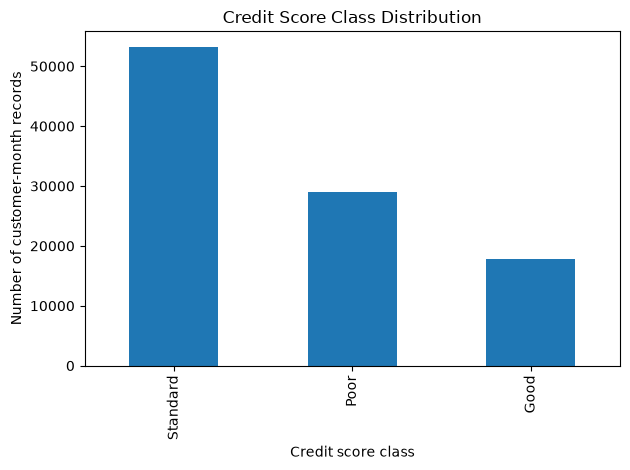

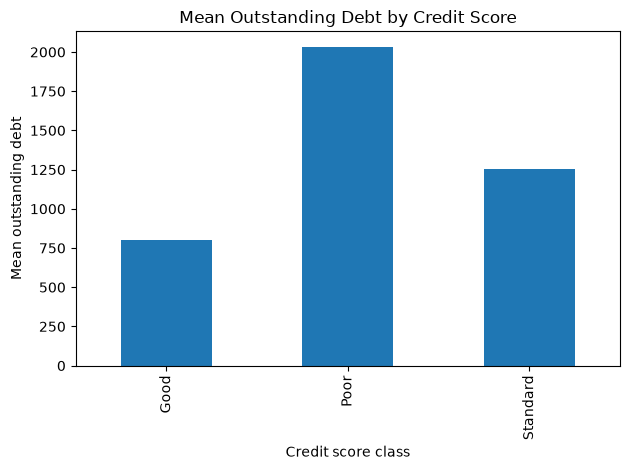

In [55]:

comparison_features = [
    "Outstanding_Debt", "Credit_Utilization_Ratio",
    "Num_of_Delayed_Payment", "Interest_Rate"
]
class_data = df[df["Credit_Score"].isin(["Good", "Poor"])].copy()

class_summary = class_data.groupby("Credit_Score")[comparison_features].agg(
    ["mean", "median"]
).T
display(class_summary.round(3))

class_counts = df["Credit_Score"].value_counts().to_frame("Records")
display(class_counts)

# Plot class distribution
df["Credit_Score"].value_counts().plot(kind="bar", title="Credit Score Class Distribution")
plt.xlabel("Credit score class")
plt.ylabel("Number of customer-month records")
plt.tight_layout()
plt.show()

# Plot average outstanding debt by class
df.groupby("Credit_Score")["Outstanding_Debt"].mean().plot(
    kind="bar", title="Mean Outstanding Debt by Credit Score"
)
plt.xlabel("Credit score class")
plt.ylabel("Mean outstanding debt")
plt.tight_layout()
plt.show()



In [56]:
# 13. Load phase: export the processed dataset

model_ready.to_csv(OUTPUT_FILE, index=False)

print("Export completed:", OUTPUT_FILE.resolve())
print("Final dataset dimensions:", model_ready.shape)
print("Remaining missing cells:", int(model_ready.isna().sum().sum()))
print("Final duplicate rows:", int(model_ready.duplicated().sum()))
print("File size (MB):", round(OUTPUT_FILE.stat().st_size / (1024**2), 2))



Export completed: C:\Users\Admin\creditscoreclassification\credit_score_cleaned.csv
Final dataset dimensions: (100000, 26)
Remaining missing cells: 59680
Final duplicate rows: 0
File size (MB): 28.47


In [58]:

# 14. Data mining readiness and conclusion

groups = data.loc[df.index, "Customer_ID"].astype(str)
target = df["Credit_Score"].astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(df, target, groups=groups))

print("Training records:", len(train_idx))
print("Testing records:", len(test_idx))
print("Customers in training:", groups.iloc[train_idx].nunique())
print("Customers in testing:", groups.iloc[test_idx].nunique())
print("Customer overlap:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

print("\nConclusion:")
print("The raw credit-score data was extracted, profiled, cleaned, transformed,")
print("reduced, summarized and exported. It is ready for further classification")
print("experiments after train-only encoding and scaling.")



Training records: 80000
Testing records: 20000
Customers in training: 10000
Customers in testing: 2500
Customer overlap: 0

Conclusion:
The raw credit-score data was extracted, profiled, cleaned, transformed,
reduced, summarized and exported. It is ready for further classification
experiments after train-only encoding and scaling.
